![Water quality](https://cdn-icons-png.flaticon.com/512/11707/11707251.png)

Accra, Ghana’s vibrant capital and a fast-growing city. Water is life, but supplying safe drinking water is becoming more difficult as raw water sources face increasing pressure from pollution, mining activities, and changing environmental conditions.

In this project, you will support the Odaso Water Treatment Plant by analyzing raw water quality data from the Oda River. The goal is to identify patterns in turbidity, pH, temperature, and alkalinity, then build a predictive model that can help determine the optimal coagulant dosage for more efficient and cost-effective treatment.

This matters because coagulation-flocculation is one of the most important steps in water treatment, and getting the dosage right can improve turbidity removal, reduce chemical waste, and help ensure safe water for surrounding communities.

## The Data

You have been provided with a single dataset for this study. A brief summary of the key variables is shown below.

# water_quality.csv

| Column | Description |
|--------|-------------|
| `Date` | The date the the reading was taken. |
| `Year` | The year of sampling. |
| `Month` | The month the the reading was taken. |
| `pH` | Indicates how acidic or alkaline the water is. |
| `Turbidity` | Measures how cloudy the raw water is. Higher values usually indicate more suspended particles (NTU). |
| `Conductivity` | Measures  how conductive the water is (µS/cm). |
| `Temperature` | The raw water temperature at the time of sampling (°C). |
| `Coagulant_Dosage` | The amount of coagulant used or determined to be optimal during jar tests (kg/day). |

## Importing Libraries and Data

In [333]:
# library for loading and preprocessing
import numpy as np
import pandas as pd

# library for visualization
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# library for data scaling
from sklearn.preprocessing import StandardScaler

# library for computing classification metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# library for ml algorithms
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# library for hyperparameter tuning
from sklearn.model_selection import GridSearchCV


import warnings 
warnings.filterwarnings("ignore")
seed = 10

In [334]:
# Load data
data = pd.read_csv('water_quality.csv')

# Display first few rows of data
data.head()

,Date,Year,Month,pH,Turbidity (NTU),Conductivity / EC (µS/cm),Temperature (°C),Coagulant Dosage (kg/day)
0,02/01/2011,2011,1,7.32,2209.0,238.2,28.1,1059.8
1,05/01/2011,2011,1,7.44,2583.3,252.8,27.7,946.5
2,09/01/2011,2011,1,7.32,2304.9,224.7,28.4,979.4
3,12/01/2011,2011,1,7.32,2371.9,258.8,27.7,1030.5
4,16/01/2011,2011,1,7.40,3058.3,237.0,28.2,759.7


In [335]:
# Display last few rows of data
data.tail()

,Date,Year,Month,pH,Turbidity (NTU),Conductivity / EC (µS/cm),Temperature (°C),Coagulant Dosage (kg/day)
1531,12/12/2026,2026,12,NaN,NaN,NaN,NaN,NaN
1532,16/12/2026,2026,12,NaN,NaN,NaN,NaN,NaN
1533,19/12/2026,2026,12,NaN,NaN,NaN,NaN,NaN
1534,23/12/2026,2026,12,NaN,NaN,NaN,NaN,NaN
1535,26/12/2026,2026,12,NaN,NaN,NaN,NaN,NaN


In [336]:
# Data information
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1536 entries, 0 to 1535
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       1536 non-null   str    
 1   Year                       1536 non-null   int64  
 2   Month                      1536 non-null   int64  
 3   pH                         1440 non-null   float64
 4   Turbidity (NTU)            1440 non-null   float64
 5   Conductivity / EC (µS/cm)  1440 non-null   float64
 6   Temperature (°C)           1440 non-null   float64
 7   Coagulant Dosage (kg/day)  1440 non-null   float64
dtypes: float64(5), int64(2), str(1)
memory usage: 111.1 KB


In [337]:
# Check for missing or null values
data.isna().sum()

Date                          0
Year                          0
Month                         0
pH                           96
Turbidity (NTU)              96
Conductivity / EC (µS/cm)    96
Temperature (°C)             96
Coagulant Dosage (kg/day)    96
dtype: int64

In [338]:
# Check for duplicated records
data.duplicated().sum()

np.int64(0)

## Data Cleaning and Validation

In [339]:
data.isna().sum()

Date                          0
Year                          0
Month                         0
pH                           96
Turbidity (NTU)              96
Conductivity / EC (µS/cm)    96
Temperature (°C)             96
Coagulant Dosage (kg/day)    96
dtype: int64

In [340]:
# Remove rows with missing values
data = data.dropna()

data.isna().sum()

Date                         0
Year                         0
Month                        0
pH                           0
Turbidity (NTU)              0
Conductivity / EC (µS/cm)    0
Temperature (°C)             0
Coagulant Dosage (kg/day)    0
dtype: int64

Missing values were dropped since they are just unrecorded data, Missing Completely At Random (MCAR).

In [341]:
# Rename column names
data.columns = ['date', 'year', 'month', 'ph', 'turbidity',
       'conductivity', 'temperature',
       'coagulant_dosage']

data.head()

,date,year,month,ph,turbidity,conductivity,temperature,coagulant_dosage
0,02/01/2011,2011,1,7.32,2209.0,238.2,28.1,1059.8
1,05/01/2011,2011,1,7.44,2583.3,252.8,27.7,946.5
2,09/01/2011,2011,1,7.32,2304.9,224.7,28.4,979.4
3,12/01/2011,2011,1,7.32,2371.9,258.8,27.7,1030.5
4,16/01/2011,2011,1,7.40,3058.3,237.0,28.2,759.7


In [343]:
# Convert the 'date' column to datetime format
data['date'] = pd.to_datetime(data['date'], format='%d/%m/%Y')
data.dtypes

date                datetime64[us]
year                         int64
month                        int64
ph                         float64
turbidity                  float64
conductivity               float64
temperature                float64
coagulant_dosage           float64
dtype: object

#### Data Cleaning and Validation Summary
- Dropped all null values 

- Renamed column headers for readability

- Converted the date variable to datetime dtype

## Data Exploratory Analysis

In [344]:
# Data distribution
data.describe().round(2)

,date,year,month,ph,turbidity,conductivity,temperature,coagulant_dosage
count,1440,1440.00,1440.00,1440.00,1440.00,1440.00,1440.00,1440.00
mean,2018-06-29 14:08:00,2018.00,6.50,7.20,1913.95,360.73,26.71,678.73
min,2011-01-02 00:00:00,2011.00,1.00,5.95,31.90,24.10,22.10,108.30
25%,2014-09-30 12:00:00,2014.00,3.75,6.98,633.45,247.65,26.00,438.92
50%,2018-06-29 00:00:00,2018.00,6.50,7.25,1465.70,355.40,26.70,658.30
75%,2022-03-27 18:00:00,2022.00,9.25,7.46,2756.45,453.95,27.40,890.65
max,2025-12-26 00:00:00,2025.00,12.00,8.19,14699.40,889.80,32.60,2108.20
std,NaN,4.32,3.45,0.37,1736.56,143.74,1.28,318.08


There is skewness in the turbidity variable suggesting possible outliers

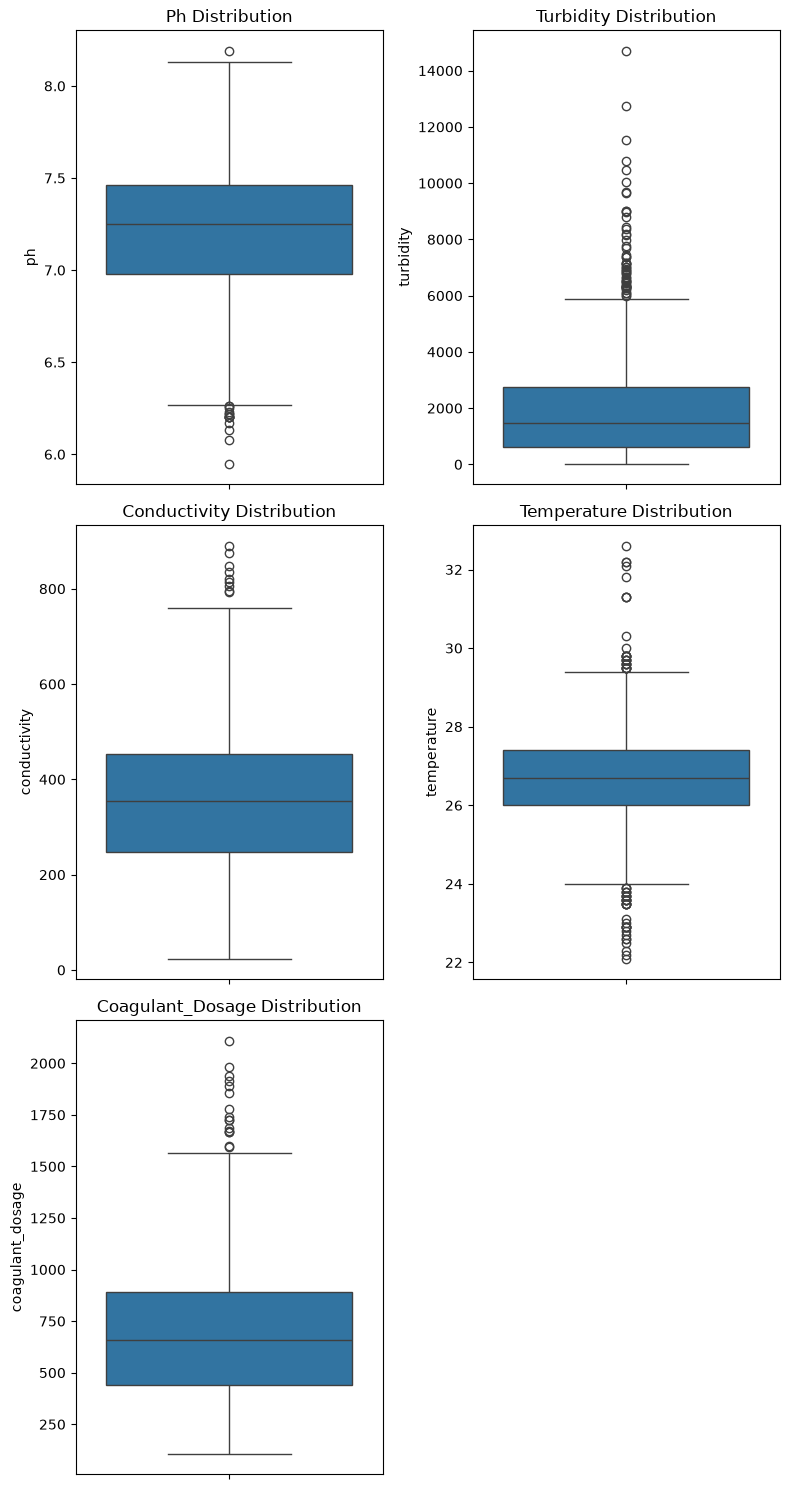

In [345]:
# Investigating skewness with visualization

interest_column = ['ph', 'turbidity', 'conductivity', 'temperature', 'coagulant_dosage']

plt.figure(figsize=(8, 15))
for index, col in enumerate(interest_column):
    plt.subplot(3, 2, index + 1)  # Changed from (2, 2, ...) to (3, 2, ...)
    sns.boxplot(data=data, y=col)
    plt.title(f'{col} Distribution'.title())
plt.tight_layout()
plt.show()

The box plot visualization indicates that there are outliers pH, Turbidity, Conductivity, Temperature, Coagulant_dosage variables. With this, these variables need to be scaled before feeding them into the ML model

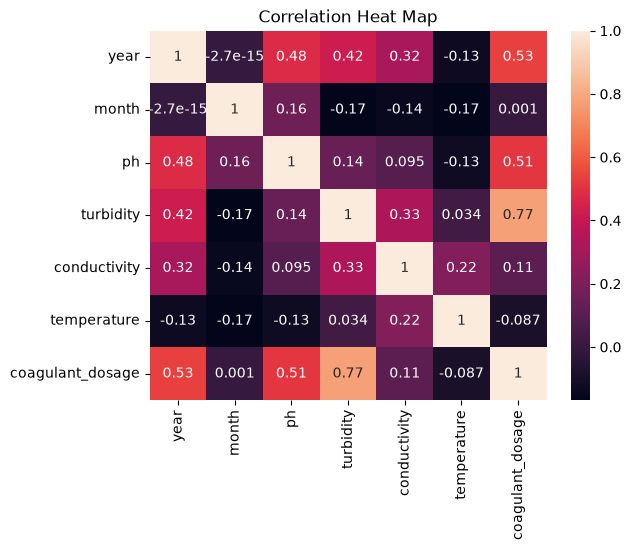

In [346]:
# heatmap correlation
sns.heatmap(data.select_dtypes(include='number').corr(), annot=True)
plt.title('Correlation Heat Map')
plt.show()

- Turbidity has the highest positive correlation (0.77) with coagulant dosage
- Year and pH have a moderate correlation with coagulant dosage

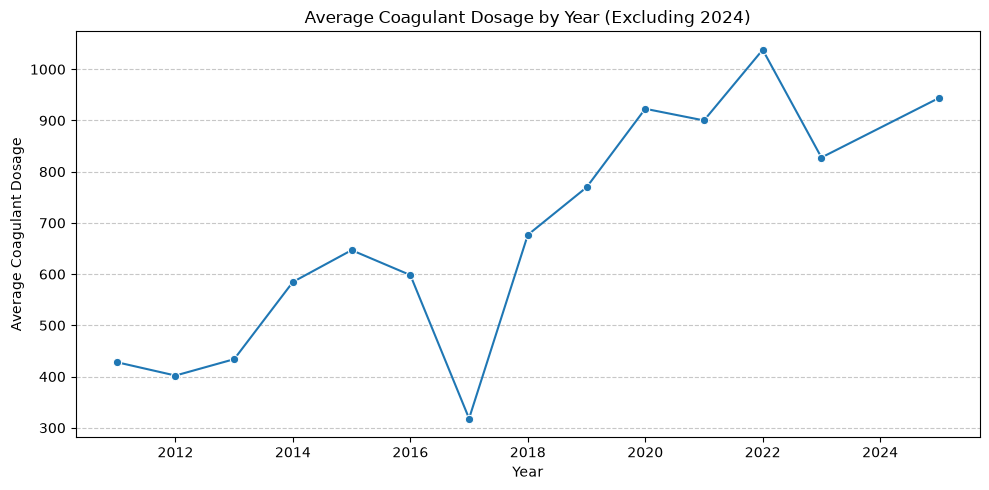

In [347]:
# Investigate further into the correlations

# By Year
# Calculate average coagulant dosage per year
yearly_avg = data.groupby('year')['coagulant_dosage'].mean().reset_index()

# Exclude year 2024
yearly_avg_excl_2024 = yearly_avg[yearly_avg['year'] != 2024]

plt.figure(figsize=(10, 5))
sns.lineplot(data=yearly_avg_excl_2024, x='year', y='coagulant_dosage', marker='o')
plt.xlabel('Year')
plt.ylabel('Average Coagulant Dosage')
plt.title('Average Coagulant Dosage by Year (Excluding 2024)')
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Coagulant dosage has steady upwards trend with year suggesting water quality decreasing as time goes on

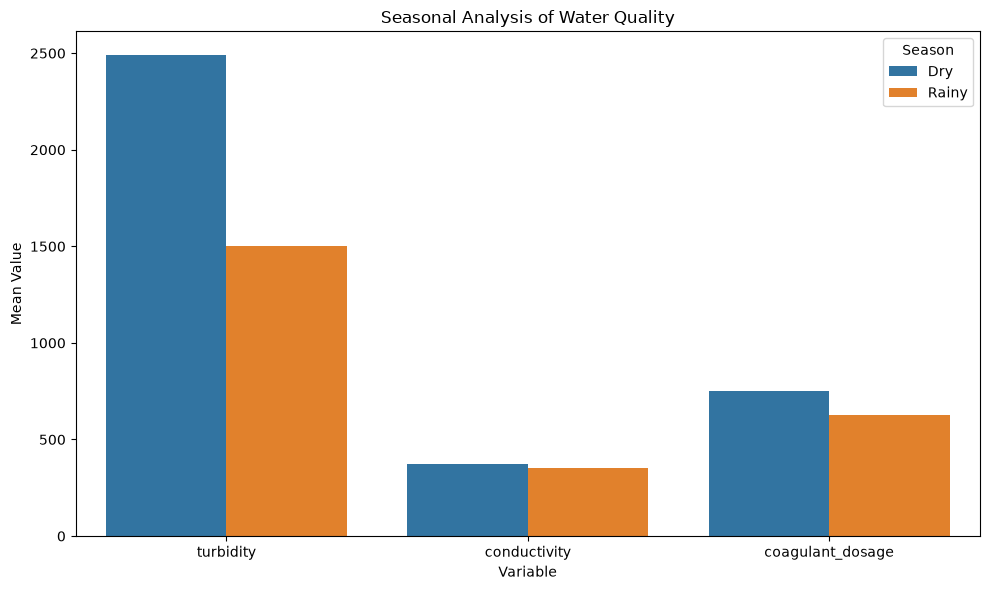

In [348]:
# Seasonal analysis: Assign season based on month (Ghana: Rainy - Apr to Oct, Dry - Nov to Mar)
def assign_season(month):
    # Rainy season: April (4) to October (10)
    if 4 <= month <= 10:
        return 'Rainy'
    else:
        return 'Dry'

# Ensure 'month' column exists; if not, extract from a 'date' column
if 'month' not in data.columns:
    if 'date' in data.columns:
        data['month'] = pd.to_datetime(data['date']).dt.month
    else:
        raise ValueError("No 'month' or 'date' column found in data.")

data['season'] = data['month'].apply(assign_season)

# Group by season and calculate mean of relevant variables
seasonal_means = data.groupby('season')[['turbidity', 'conductivity', 'coagulant_dosage']].mean().reset_index()

# Visualize seasonal differences for coagulant dosage and other variables
plt.figure(figsize=(10, 6))
sns.barplot(data=seasonal_means.melt(id_vars='season', var_name='Variable', value_name='Mean Value'),
            x='Variable', y='Mean Value', hue='season')
plt.title('Seasonal Analysis of Water Quality')
plt.ylabel('Mean Value')
plt.xlabel('Variable')
plt.legend(title='Season')
plt.tight_layout()
plt.show()

Interestingly, the dry seasons records the high levels of turbidity and conductivity which leads to higher coagulant dosages

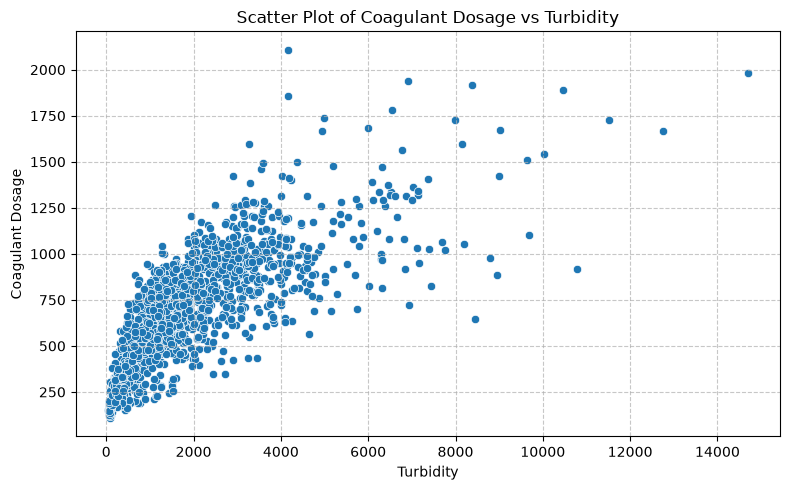

In [349]:
# By Turbidity
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x='turbidity', y='coagulant_dosage')
plt.xlabel('Turbidity')
plt.ylabel('Coagulant Dosage')
plt.title('Scatter Plot of Coagulant Dosage vs Turbidity')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

As turbidity increases with increasing coagulant dosage

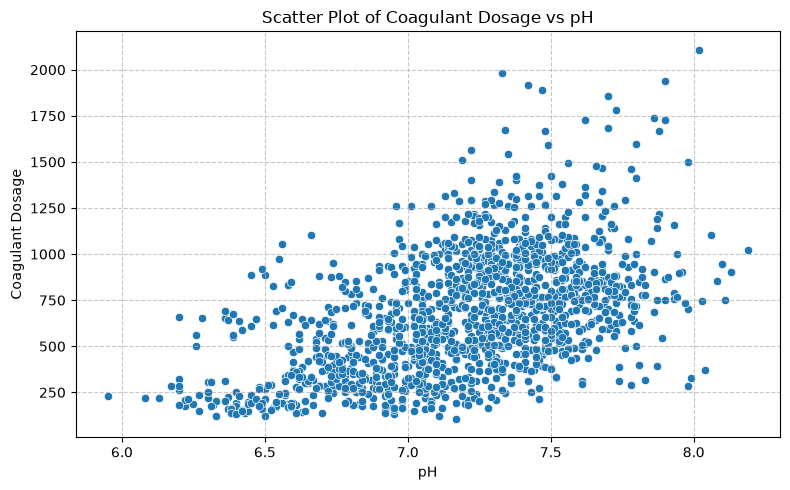

In [350]:
# By pH
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x='ph', y='coagulant_dosage')
plt.xlabel('pH')
plt.ylabel('Coagulant Dosage')
plt.title('Scatter Plot of Coagulant Dosage vs pH')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

There is no strong correlation between pH and coagulant dosage

#### Data Exploratory Analysis Summary
- There is skewness in the pH, Turbidity, Conductivity, Temperature, Coagulant_dosage variables. With this, these variables need to be scaled before feeding them into the ML model 

- There is a strong positive correlation between coagulant dosage and turbidity. pH has a moderate correlation (0.51) with coagulant dosage.

- Coagulant dosage has steady upwards trend with year suggesting water quality decreasing as time goes on

---
## Machine Learning

#### Feature Engineering

In [ ]:
# Feature engineering for time series data

data = data.sort_values('date')
data = data.set_index('date')

# Create time-based features
#data['year'] = data.index.year
#data['month'] = data.index.month
data['day'] = data.index.day
data['dayofweek'] = data.index.dayofweek
data['quarter'] = data.index.quarter


# Add a natural log-transformed column for coagulant dosage
data['coagulant_dosage_log'] = np.log(data['coagulant_dosage'])

In [352]:
# Export needed features for streamlit-deployment
data[['year', 'month', 'day', 'dayofweek', 'quarter', 'ph', 'turbidity', 'conductivity', 'temperature', 'coagulant_dosage_log']].to_csv('water_quality_cleaned.csv', index=False)

#### Data Preprocessing

In [353]:
def preprocessing(dataframe, scaler_list: list):
    """
    Preprocesses the input dataframe by dropping specified columns, scaling selected numerical features,
    and encoding categorical variables.

    Parameters
    ----------
    dataframe : pd.DataFrame
        The input dataframe to preprocess.
    scaler_list : list
        List of column names in the dataframe to be scaled using StandardScaler.

    Returns
    -------
    pd.DataFrame
        The preprocessed dataframe with selected columns scaled,
        and categorical variables one-hot encoded.
    """
  
    # instantiate scaler
    scaler = StandardScaler()

    # fit transform to model
    dataframe[scaler_list] = scaler.fit_transform(dataframe[scaler_list])

    # encode categorical features
    dataframe = pd.get_dummies(dataframe)

    return dataframe

In [354]:
interest_column = ['ph', 'turbidity', 'conductivity', 'temperature']

# call the function
data = preprocessing(data, interest_column)
data.head()

,year,month,ph,turbidity,conductivity,temperature,coagulant_dosage,day,dayofweek,quarter,coagulant_dosage_log,season_Dry,season_Rainy
date,,,,,,,,,,,,,
2011-01-02,2011,1,0.312857,0.169964,-0.852723,1.080190,1059.8,2,6,1,6.965835,True,False
2011-01-05,2011,1,0.637943,0.385580,-0.751114,0.768394,946.5,5,2,1,6.852771,True,False
2011-01-09,2011,1,0.312857,0.225207,-0.946676,1.314037,979.4,9,6,1,6.886940,True,False
2011-01-12,2011,1,0.312857,0.263802,-0.709358,0.768394,1030.5,12,2,1,6.937799,True,False
2011-01-16,2011,1,0.529581,0.659204,-0.861074,1.158139,759.7,16,6,1,6.632924,True,False


#### Data Splitting

In [355]:
# This splitting method divides the dataset into training and testing sets based on row order. This approach is often used for time series data to preserve temporal order, but for randomly ordered data, train_test_split from sklearn is usually preferred.

train_size = int(len(data) * 0.8)  # Calculate 90% of the data length
train_data = data[:train_size]     # Select the first 90% of rows as training data


# Dependent variables
x_features = ['year', 'month', 'day', 'dayofweek', 'quarter', 'ph', 'turbidity', 'conductivity', 'temperature']
X_train = train_data[x_features] 
# Target variable
y_train = train_data['coagulant_dosage_log'] 

test_data = data[train_size:]      # Select the remaining 20% as testing data
X_test = test_data[x_features]
y_test = test_data['coagulant_dosage_log']

In [356]:
print(f'Shape of X_train: {X_train.shape}')
X_train.head()

Shape of X_train: (1152, 9)


,year,month,day,dayofweek,quarter,ph,turbidity,conductivity,temperature
date,,,,,,,,,
2011-01-02,2011,1,2,6,1,0.312857,0.169964,-0.852723,1.080190
2011-01-05,2011,1,5,2,1,0.637943,0.385580,-0.751114,0.768394
2011-01-09,2011,1,9,6,1,0.312857,0.225207,-0.946676,1.314037
2011-01-12,2011,1,12,2,1,0.312857,0.263802,-0.709358,0.768394
2011-01-16,2011,1,16,6,1,0.529581,0.659204,-0.861074,1.158139


In [357]:
print(f'Shape of y_train: {y_train.shape}')
y_train.head()

Shape of y_train: (1152,)


date
2011-01-02    6.965835
2011-01-05    6.852771
2011-01-09    6.886940
2011-01-12    6.937799
2011-01-16    6.632924
Name: coagulant_dosage_log, dtype: float64

#### Model Development

In [358]:
# initiate regression models
reg_models = {
    'Linear Regression': LinearRegression(),
    'Random Forest Regressor': RandomForestRegressor(random_state=10, n_jobs=-1),
    'XGBoost Regressor': XGBRegressor(random_state=10, n_jobs=-1),
}

def regression_algorithms(X_train, X_test, y_train, y_test):
    """
    Trains and evaluates multiple regression algorithms on the provided data.

    Parameters
    ----------
    X_train : array-like
        Training features.
    X_test : array-like
        Test features.
    y_train : array-like
        Training target values.
    y_test : array-like
        Test target values.

    Returns
    -------
    None
        Displays summary tables of model evaluation metrics (MAE, RMSE, R^2) for both train and test sets.
    """
    print('TRAIN DATA MODEL METRICS')
    summary_train = {'Metric': ['MAE', 'RMSE', 'R^2']}
    
    # Optional: Dictionary to save trained models if needed
    global trained_models
    trained_models = {}

    for name, model in reg_models.items():
        model.fit(X_train, y_train)
        pred_train = model.predict(X_train)
        
        mae = mean_absolute_error(y_train, pred_train)
        rmse = np.sqrt(mean_squared_error(y_train, pred_train))
        r2 = r2_score(y_train, pred_train)
        
        summary_train[name] = [round(mae, 3), round(rmse, 3), round(r2, 3)]

        # saving the model with a valid variable name in a dictionary
        trained_models[name.replace(' ', '_').lower()] = model
    
    table_train = pd.DataFrame(summary_train)
    display(table_train.set_index('Metric').T)
    
    print('\nTEST DATA MODEL METRICS')
    summary_test = {'Metric': ['MAE', 'RMSE', 'R^2']}
    plt.figure(figsize=(20, 10))
    
    for idx, (name, model) in enumerate(reg_models.items()):
        model.fit(X_train, y_train)
        pred_test = model.predict(X_test)
        
        mae = mean_absolute_error(y_test, pred_test)
        rmse = np.sqrt(mean_squared_error(y_test, pred_test))
        r2 = r2_score(y_test, pred_test)
        
        summary_test[name] = [round(mae, 3), round(rmse, 3), round(r2, 3)]
        
        # Optional: Plot predictions vs true values for each model
        plt.subplot(2, 3, idx+1)
        plt.scatter(y_test, pred_test, alpha=0.5)
        plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
        plt.xlabel('True Values')
        plt.ylabel('Predictions')
        plt.title(name)
    
    table_test = pd.DataFrame(summary_test)
    display(table_test.set_index('Metric').T)
    
    plt.tight_layout()
    plt.show()

TRAIN DATA MODEL METRICS


Metric,MAE,RMSE,R^2
Linear Regression,0.228,0.295,0.723
Random Forest Regressor,0.048,0.062,0.988
XGBoost Regressor,0.014,0.019,0.999



TEST DATA MODEL METRICS


Metric,MAE,RMSE,R^2
Linear Regression,0.164,0.212,0.502
Random Forest Regressor,0.138,0.170,0.679
XGBoost Regressor,0.144,0.183,0.627


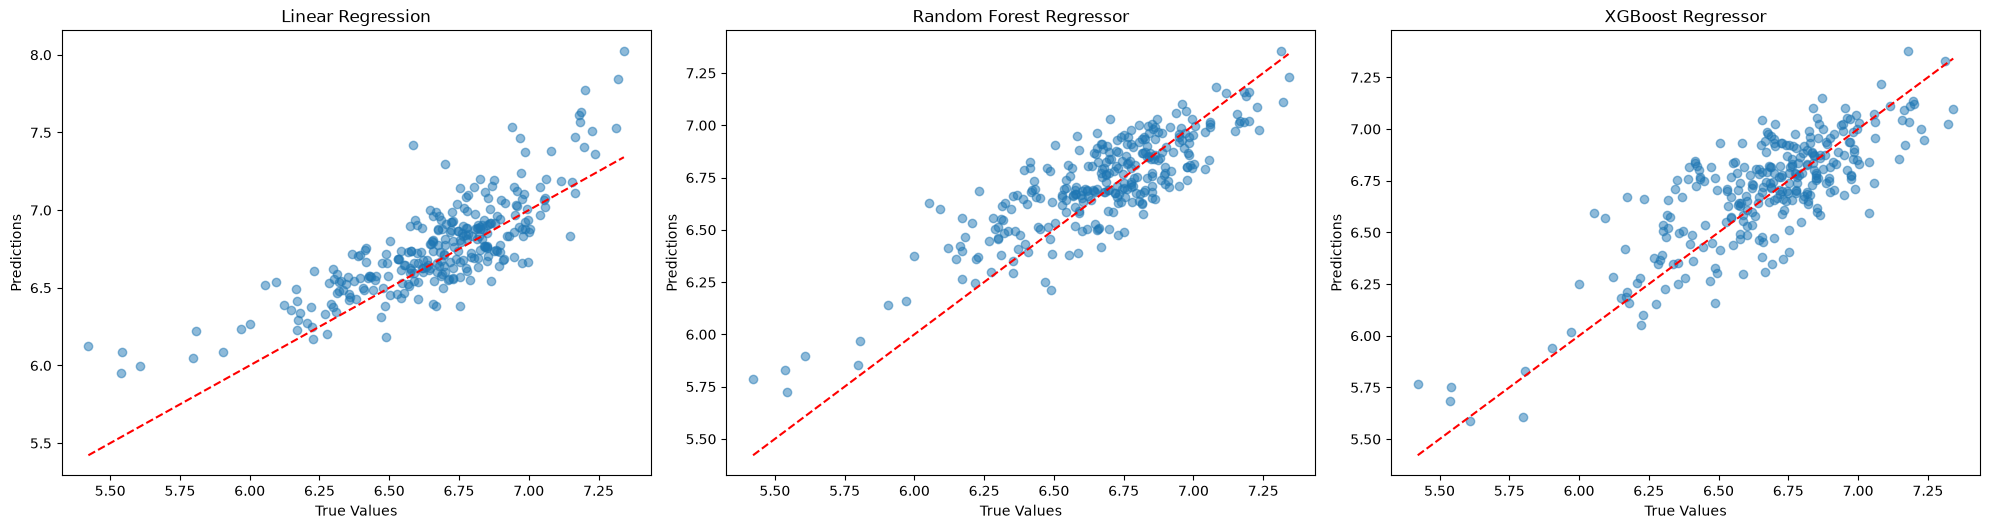

In [359]:
# call function
regression_algorithms(X_train, X_test, y_train, y_test)

Random Forest and XGBoost have similar performance. Final conclusion will be made after we tune the models

#### Hyperparameter Tuning

In [360]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

# Define the base estimator
rf = RandomForestRegressor(random_state=seed, n_jobs=-1)

# Define the parameter grid for hyperparameter tuning, including 'criterion' and 'max_samples'
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
}

# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    n_jobs=-1,
    scoring='r2',
    verbose=0
)

# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

# Best R-squared score and parameters
best_r2 = grid_search.best_score_
best_params = grid_search.best_params_

print(f'Best R-squared Score: {best_r2}')
print(f'Best Parameters: {best_params}')

Best R-squared Score: 0.71041630360376
Best Parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [361]:
# Define the base estimator
xgb = XGBRegressor(random_state=seed, objective='reg:squarederror', n_jobs=-1)

# Define the parameter grid for hyperparameter tuning
param_grid_xgb = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'gamma': [0, 0.1, 0.2]
}

# Set up GridSearchCV
grid_search_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid_xgb,
    cv=5,
    n_jobs=-1,
    scoring='r2',
    verbose=0  # Suppress output
)

# Fit GridSearchCV to the training data
grid_search_xgb.fit(X_train, y_train)

# Best R-squared score and parameters
best_r2_xgb = grid_search_xgb.best_score_
best_params_xgb = grid_search_xgb.best_params_

print(f'Best R-squared Score: {best_r2_xgb}')
print(f'Best Parameters: {best_params_xgb}')

Best R-squared Score: 0.7666041132157939
Best Parameters: {'colsample_bytree': 1.0, 'gamma': 0.1, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.6}


In [362]:
# initiate regression models
reg_models = {
    'Linear Regression': LinearRegression(),
    'Random Forest Regressor': RandomForestRegressor(random_state=seed, n_jobs=-1, max_depth=20, min_samples_leaf=2, min_samples_split=2, n_estimators=50),
    'XGBoost Regressor': XGBRegressor(random_state=seed, n_jobs=-1, colsample_bytree=1.0, gamma=0.1, learning_rate=0.1, max_depth=3, n_estimators=200, subsample=0.6),
}


def regression_algorithms_tuned(X_train, X_test, y_train, y_test):
    """
    Trains and evaluates multiple regression algorithms on the provided data.

    Parameters
    ----------
    X_train : array-like
        Training features.
    X_test : array-like
        Test features.
    y_train : array-like
        Training target values.
    y_test : array-like
        Test target values.

    Returns
    -------
    None
        Displays summary tables of model evaluation metrics (MAE, RMSE, R^2) for both train and test sets.
    """
    print('TRAIN DATA MODEL METRICS')
    summary_train = {'Metric': ['MAE', 'RMSE', 'R^2']}
    
    # Optional: Dictionary to save trained models if needed
    global trained_models
    trained_models = {}

    for name, model in reg_models.items():
        model.fit(X_train, y_train)
        pred_train = model.predict(X_train)
        
        mae = mean_absolute_error(y_train, pred_train)
        rmse = np.sqrt(mean_squared_error(y_train, pred_train))
        r2 = r2_score(y_train, pred_train)
        
        summary_train[name] = [round(mae, 3), round(rmse, 3), round(r2, 3)]

        # saving the model with a valid variable name in a dictionary
        trained_models[name.replace(' ', '_').lower()] = model
    
    table_train = pd.DataFrame(summary_train)
    display(table_train.set_index('Metric').T)
    
    print('\nTEST DATA MODEL METRICS')
    summary_test = {'Metric': ['MAE', 'RMSE', 'R^2']}
    plt.figure(figsize=(20, 10))
    
    for idx, (name, model) in enumerate(reg_models.items()):
        model.fit(X_train, y_train)
        pred_test = model.predict(X_test)
        
        mae = mean_absolute_error(y_test, pred_test)
        rmse = np.sqrt(mean_squared_error(y_test, pred_test))
        r2 = r2_score(y_test, pred_test)
        
        summary_test[name] = [round(mae, 3), round(rmse, 3), round(r2, 3)]
        
        # Optional: Plot predictions vs true values for each model
        plt.subplot(2, 3, idx+1)
        plt.scatter(y_test, pred_test, alpha=0.5)
        plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
        plt.xlabel('True Values')
        plt.ylabel('Predictions')
        plt.title(name)
    
    table_test = pd.DataFrame(summary_test)
    display(table_test.set_index('Metric').T)
    
    plt.tight_layout()
    plt.show()

TRAIN DATA MODEL METRICS


Metric,MAE,RMSE,R^2
Linear Regression,0.228,0.295,0.723
Random Forest Regressor,0.059,0.078,0.981
XGBoost Regressor,0.110,0.139,0.939



TEST DATA MODEL METRICS


Metric,MAE,RMSE,R^2
Linear Regression,0.164,0.212,0.502
Random Forest Regressor,0.136,0.169,0.685
XGBoost Regressor,0.124,0.158,0.723


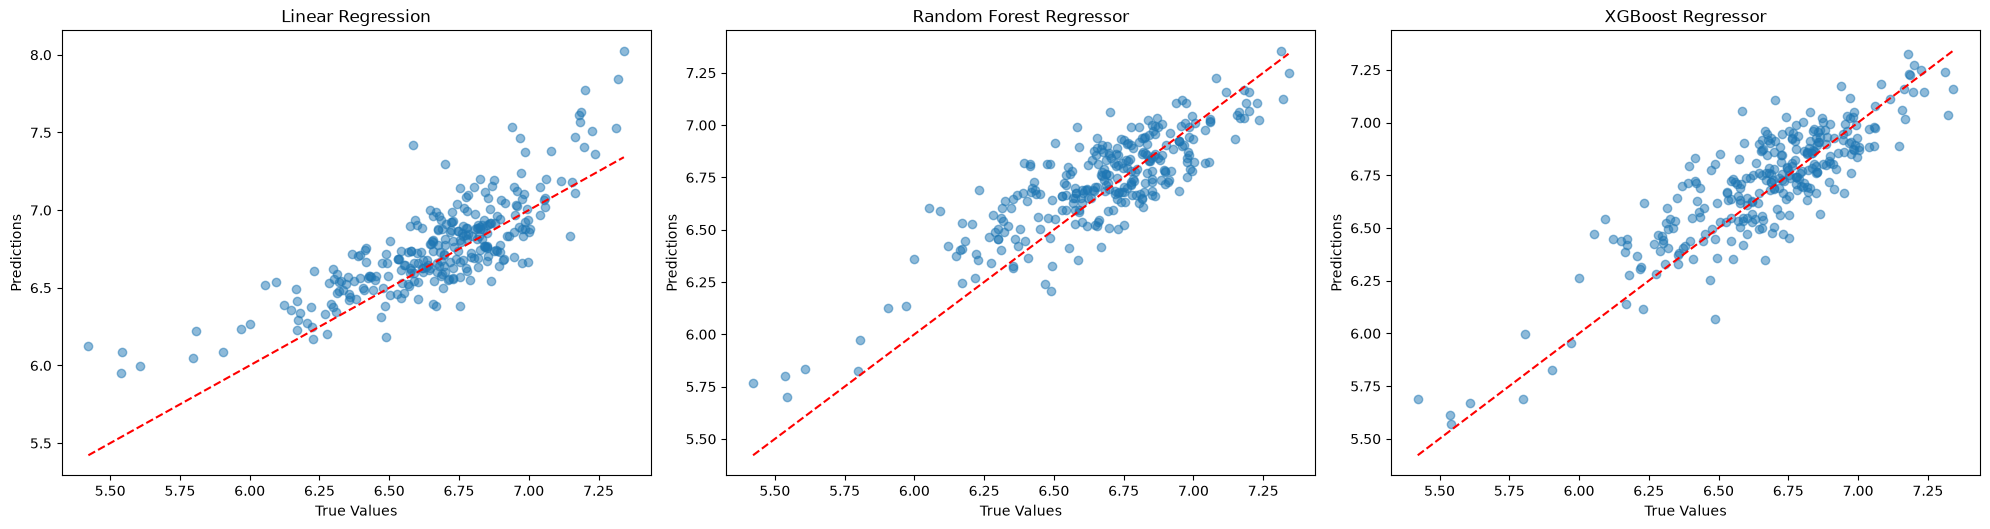

In [363]:
regression_algorithms_tuned(X_train, X_test, y_train, y_test)

#### Model Selection

- Linear Regression performed poorly because it is not for timeseries data.
- Random Forest overfitted the dataset meaning it can't generalise well to unseen data.
- XGBoost Regressor is the selected model because it had the highest R-squared score (72.3%) with the least Mean Absolute Error (MAE) and Root Mean Square Error (RMSE) scores.

#### Machine Learning Summary

1. Feature Engineering
    - More datetime features were added
    - Added a natural log of the coagulant dosage to deal with the outliers and improve model accuracy
2. Data Processing
    - Standard Scaler was used to scale the skewed nutritional information columns for model training

3. Data Splitting
    - Data was splitted into 80% for training and 20% for testing/ validation

4. Model Training and Evaluation
    - Three regression models were trained and XGBoost Regressor model was selected because it had the highest R-squared score with the least Mean Absolute Error (MAE) and Root Mean Square Error (RMSE) scores

5. Hyperparameter Tuning
    - Used GridSearchCV to tune the selected model.

## Recommendation

More dataset is required to improve the performance of the model